In [3]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster, HeatMap

df = pd.read_csv("airports-india.csv")

df.columns = df.columns.str.strip()

df = df.dropna(subset=["latitude", "longitude"])
df = df[
    df["latitude"].between(6, 38) &
    df["longitude"].between(68, 98)
]

print("Total airports:", len(df))
print(df.head())

Total airports: 201
                                             name  latitude  longitude  \
0                                  Mumbai Airport  19.08869   72.86792   
1             Indira Gandhi International Airport  28.56650   77.10309   
2  Sardar Vallabhbhai Patel International Airport  23.07724   72.63465   
3     Sri Guru Ram Dass Jee International Airport  31.70959   74.79726   
4                   Chennai International Airport  12.98833   80.16578   

  country       region  elevation_m  population feature_type  geoname_id  
0   India  Maharashtra         11.0           0      airport     6301032  
1   India        Delhi        236.0           0      airport     6301872  
2   India      Gujarat         57.0           0      airport     6301029  
3   India       Punjab        230.0           0      airport     6301092  
4   India   Tamil Nadu         15.0           0      airport     6301127  


In [4]:
m = folium.Map(
    location=[22.5, 79],
    zoom_start=5
)

for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=4,
        popup=row["name"],
        tooltip=row["name"],
        color="blue",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m.save("point_map.html")
print("Point map saved!")

Point map saved!


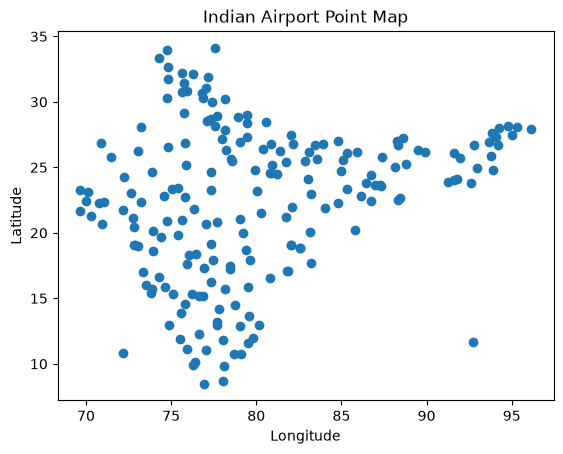

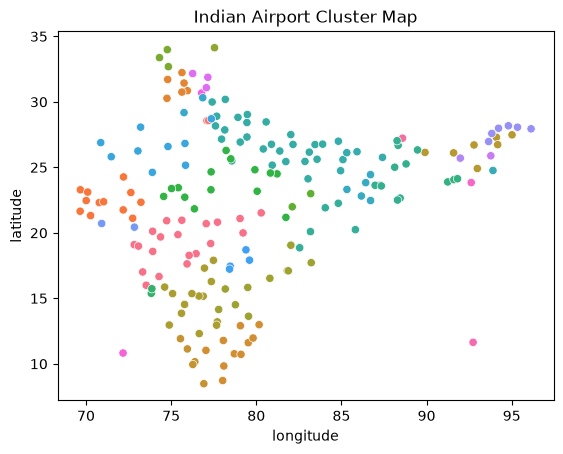

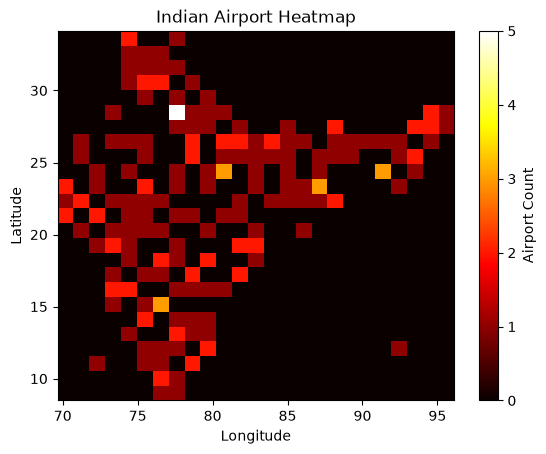

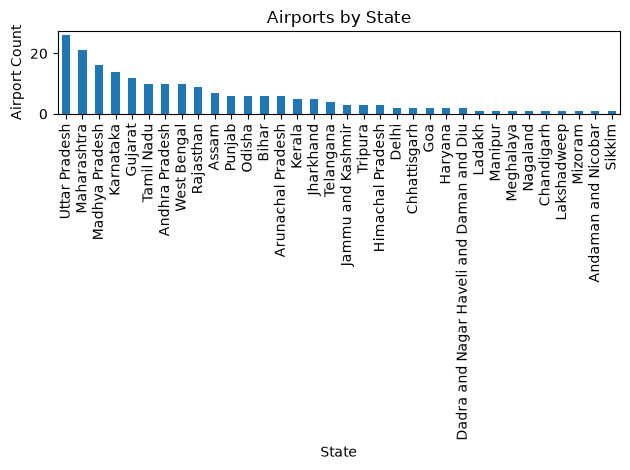

ValueError: DataFrame index must be unique for orient='index'.

In [11]:


import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

# Load dataset
df = pd.read_csv("airports-india.csv")
df.columns = df.columns.str.strip()
df = df.dropna(subset=["latitude", "longitude"])
df = df[df["latitude"].between(6, 38) &
        df["longitude"].between(68, 98)]

# 1. Point Map
plt.figure()
plt.scatter(df.longitude, df.latitude)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Indian Airport Point Map")
plt.show()

# 2. Cluster Map
plt.figure()
sns.scatterplot(data=df, x="longitude", y="latitude",
                hue="region", legend=False)
plt.title("Indian Airport Cluster Map")
plt.show()

# 3. Heatmap
plt.figure()
plt.hist2d(df.longitude, df.latitude, bins=25, cmap="hot")
plt.colorbar(label="Airport Count")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Indian Airport Heatmap")
plt.show()

# 4. Airport Count by State
plt.figure()
df["region"].value_counts().plot(kind="bar")
plt.xlabel("State")
plt.ylabel("Airport Count")
plt.title("Airports by State")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 5. Flow Map (sample connections)
routes = [
    ("Mumbai Airport", "Indira Gandhi International Airport"),
    ("Indira Gandhi International Airport",
     "Chennai International Airport"),
    ("Mumbai Airport",
     "Sardar Vallabhbhai Patel International Airport")
]

coords = df.set_index("name")[["latitude", "longitude"]].to_dict("index")

plt.figure()
plt.scatter(df.longitude, df.latitude, s=10)

for src, dst in routes:
    if src in coords and dst in coords:
        a, b = coords[src], coords[dst]
        plt.plot([a["longitude"], b["longitude"]],
                 [a["latitude"], b["latitude"]], "r-")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Indian Airport Flow Map (Illustrative Routes)")
plt.show()
